# Kronos_GUI v1: example

Charge-exchange X-ray spectra from the Kronos CX database (v3.4). `kronos_gui.py` and the `CXDatabase/` folder sit in the same
folder as this notebook; run it from there. Needs numpy, pandas and matplotlib.

In [1]:
from kronos_gui import Kronos, list_systems
systems = list_systems()                      # every ion / charge / target, its methods, and whether it has radrathe.dat
systems.head(10)

,ion,charge,target,methods,radrathe
0,Li,3,CO,mclz_nres,True
1,Li,3,CO2,mclz_nres,True
2,Li,3,H,mocc,True
3,Li,3,H2,mclz_nres,True
4,Li,3,H2O,mclz_nres,True
5,Li,3,He,mclz_nres,True
6,Li,3,N2,mclz_nres,True
7,Be,4,CO,mclz_nres,True
8,Be,4,CO2,mclz_nres,True
9,Be,4,H,mclz_nres,True


## Which data exist for one projectile

In [2]:
systems[(systems.ion == 'O') & (systems.charge == 8)]

,ion,charge,target,methods,radrathe
66,O,8,CO,mclz_nres,True
67,O,8,CO2,mclz_nres,True
68,O,8,H,"mclz_nres, qmocc, rcmd",True
69,O,8,H2,mclz_nres,True
70,O,8,H2O,mclz_nres,True
71,O,8,He,mclz_nres,True
72,O,8,N2,mclz_nres,True
73,O,8,O,mclz_nres,True
74,O,8,OH,mclz_nres,True


## One system at one collision energy

`Kronos(ion, charge, target, method=None, energy=1000.0)`. The nearest tabulated energy is used (`energy_used`). Without a method,
the preferred one is taken (RCMD, QMOCC, MOCC, AOCC, TC-BGM, CTMC, CDW, then MCLZ). n-resolved files (bare projectiles) are spread
over l with `ldist` (default `'low-energy'`).

In [3]:
k = Kronos('O', 8, 'H', method='mclz_nres', energy=1000)
print(k.citation)
k.spectrum.head()                             # Energy (eV), Intensity = emission cross section (cm^2)

O8+ + H: mclz_nres (low-energy l distribution) at 987.3 eV/u (requested 1000); 124 lines. Reference: R. S. Cumbee et al 2018 ApJ 852 7; DOI 10.3847/1538-4357/aa99d8
R. S. Cumbee et al 2018 ApJ 852 7; DOI 10.3847/1538-4357/aa99d8


,Energy,Intensity
0,0.000014,1.881380e-35
1,0.000014,6.091409e-37
2,0.000041,3.803556e-35
3,0.000095,4.969613e-35
4,0.000218,1.722893e-40


In [4]:
k.line_list(top=10)                           # strongest lines: upper and lower states, series, energy, cross section

,upper,lower,series,Energy,Intensity,fraction
0,2p(2P),1s(2S),Ly-alpha,653.621657,1.734432e-15,0.230531
1,5p(2P),1s(2S),Ly-delta,836.572863,1.237699e-15,0.164508
2,5d(2D),2p(2P),,182.957694,7.100936e-16,0.094382
3,3p(2P),1s(2S),Ly-beta,774.620085,5.439259e-16,0.072296
4,4p(2P),1s(2S),Ly-gamma,816.971274,3.847656e-16,0.051141
5,5s(2S),2p(2P),,182.943994,3.431157e-16,0.045605
6,3d(2D),2p(2P),,121.027942,3.331299e-16,0.044278
7,5d(2D),3p(2P),,61.959158,2.553522e-16,0.033940
8,5f(2F),3d(2D),,61.932514,2.415677e-16,0.032108
9,5s(2S),3p(2P),,61.945454,2.408011e-16,0.032006


In [5]:
k.line_ratios()                               # n -> 1 series (Lyman for H-like, K for He-like products) relative to alpha

,series,n_upper,Energy,Intensity,ratio
0,Ly-alpha,2,653.564082,1.734817e-15,1.000000e+00
1,Ly-beta,3,774.620085,5.439259e-16,3.135350e-01
2,Ly-gamma,4,816.971274,3.847656e-16,2.217903e-01
3,Ly-delta,5,836.572863,1.237699e-15,7.134463e-01
4,Ly-epsilon,6,847.220057,2.199909e-17,1.268093e-02
5,Ly-zeta,7,853.639676,5.388126e-27,3.105875e-12


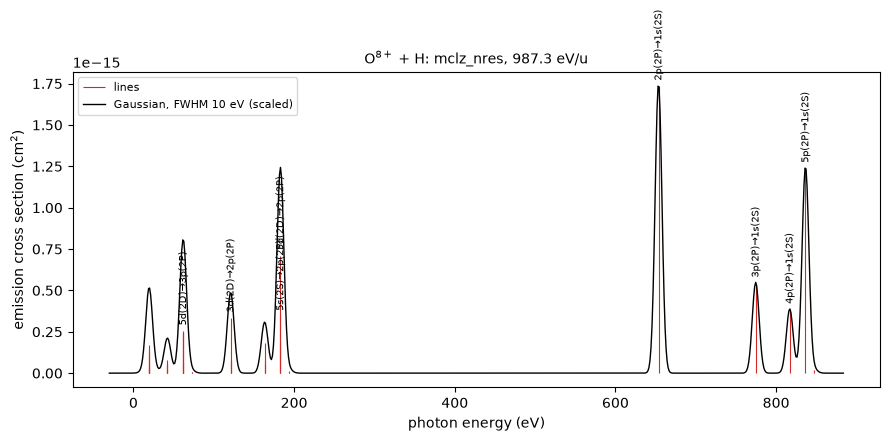

In [6]:
k.plot(fwhm=10);                              # stick spectrum and a Gaussian-convolved spectrum (FWHM in eV)

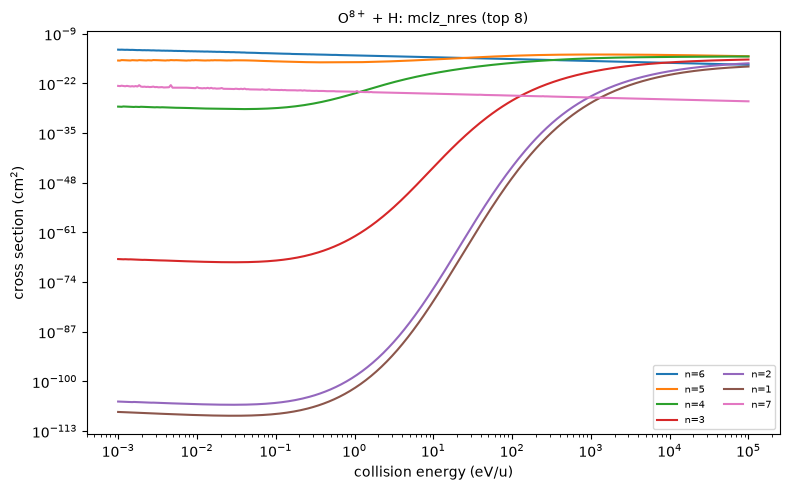

In [7]:
k.plot_cross_sections(top=8);                 # capture cross sections vs collision energy

## A He-like product and a molecular target; saving the results

Fe25+ + N2: mclz at 9.747 eV/u (requested 10); 2286 lines. Reference: P. D. Mullen et al 2016 ApJS 224 31; DOI 10.3847/0067-0049/224/2/31


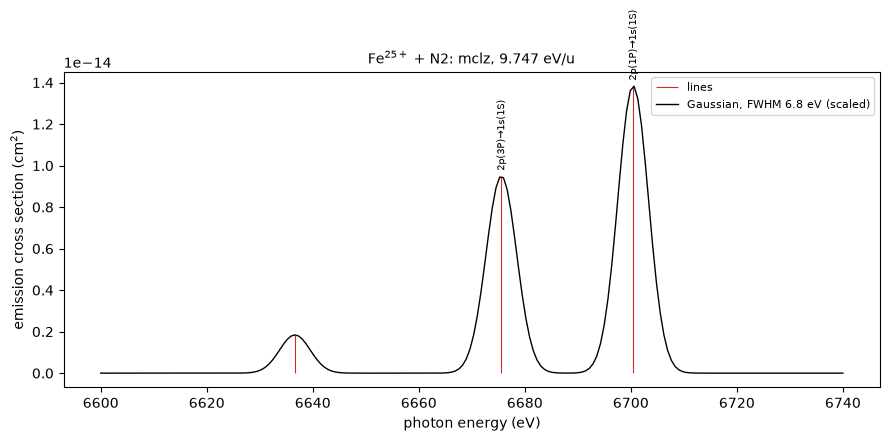

[PosixPath('results/fe25+n2_mclz_9.747eVu_spectrum.csv'),
 PosixPath('results/fe25+n2_mclz_9.747eVu_lines.csv')]

In [8]:
fe = Kronos('Fe', 25, 'N2', method='mclz', energy=10)
fe.plot(fwhm=6.8, erange=(6600, 6740), label_lines=6);
fe.save('results')                            # results/<system>_spectrum.csv and _lines.csv, reference in line 1

## Terminal and window

```
python kronos_gui.py O 8 H --energy 1000 --method mclz_nres --plot --fwhm 10
python kronos_gui.py --list Fe 25
python kronos_gui.py --gui          # needs PySide6 (pip install PySide6)
```